In [134]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from time import perf_counter

sns.set_theme(style="whitegrid")

# 1
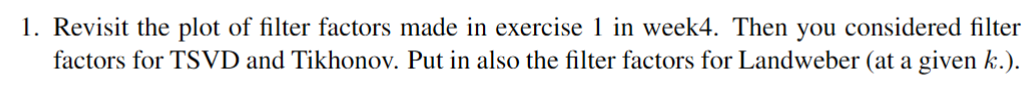

Text(39.875, 0.5, '$q(μ)$')

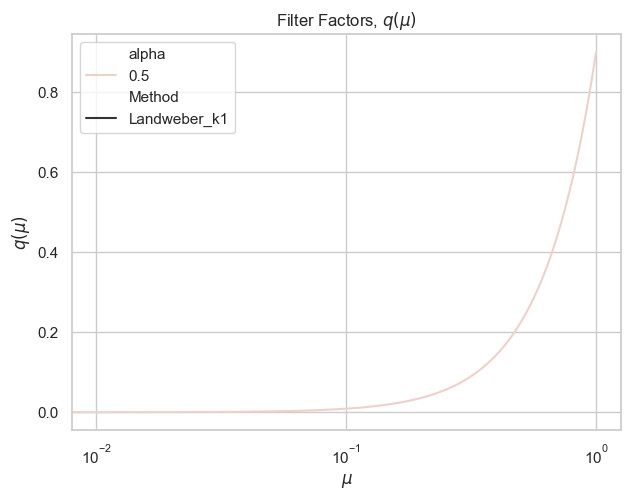

In [135]:
alpha = np.linspace(0.01, 1, 5)
mu = np.linspace(0, 1, 100)


def factor_tsvd(mu, alpha):
    return (mu > alpha**2).astype(float)


def factor_tikhonov(mu, alpha):
    return mu**2 / (mu**2 + alpha)


def factor_landweber(mu, alpha, k):
    # Omega is alpha now
    omega = 0.9
    return 1 - (1 - omega * mu**2) ** k


alpha = [0.5]
alphas_grid, mus_grid = np.meshgrid(alpha, mu)

df = pd.DataFrame(
    {
        "alpha": alphas_grid.flatten(),
        "mu": mus_grid.flatten(),
    }
)

df["TSVD"] = factor_tsvd(df["mu"], df["alpha"])
df["Tikhonov"] = factor_tikhonov(df["mu"], df["alpha"])
df["Landweber_k1"] = factor_landweber(df["mu"], df["alpha"], k=1)

value_vars = [
    # "TSVD",
    # "Tikhonov",
    "Landweber_k1",
]
dfm = pd.melt(
    df,
    id_vars=["mu", "alpha"],
    value_vars=value_vars,
    var_name="Method",
    value_name="Value",
)


plt.figure()
sns.lineplot(
    data=dfm,
    x="mu",
    y="Value",
    hue="alpha",
    style="Method",
    legend="full",
)
plt.tight_layout()
# plt.plot(mu, factor_tsvd(mu), label='TSVD')
# plt.plot(mu, factor_tikhonov(mu), label='Tikhonov')

plt.semilogx()
plt.title("Filter Factors, $q(μ)$")
plt.xlabel("$μ$")
plt.ylabel("$q(μ)$")

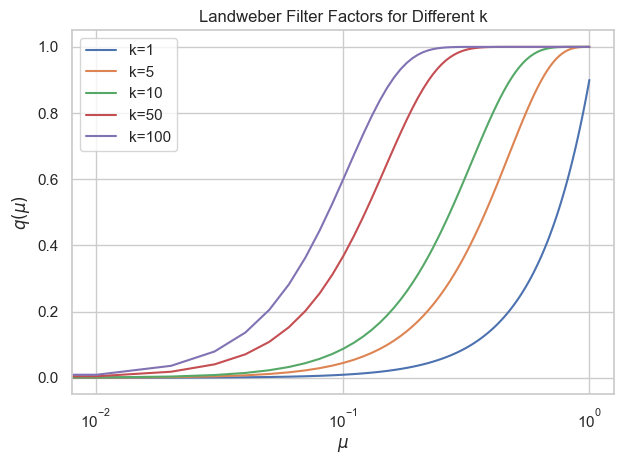

In [136]:
# To confirm see: https://www.sciencedirect.com/science/article/pii/S0098300419300159
def factor_landweber(mu, k):
    omega = 0.9
    # Note: omega < 2 / (max singular value)^2 for convergence
    return 1 - (1 - omega * mu**2) ** k

plt.figure()
for k in [1, 5, 10, 50, 100]:
    plt.semilogx(mu, factor_landweber(mu, k), label=f'k={k}')

plt.xlabel('$μ$')
plt.ylabel('$q(μ)$')
plt.title('Landweber Filter Factors for Different k')
plt.legend()
plt.tight_layout()


Comment: As we go to higher K we filter out less and less of the low μ 'modes'

# 2
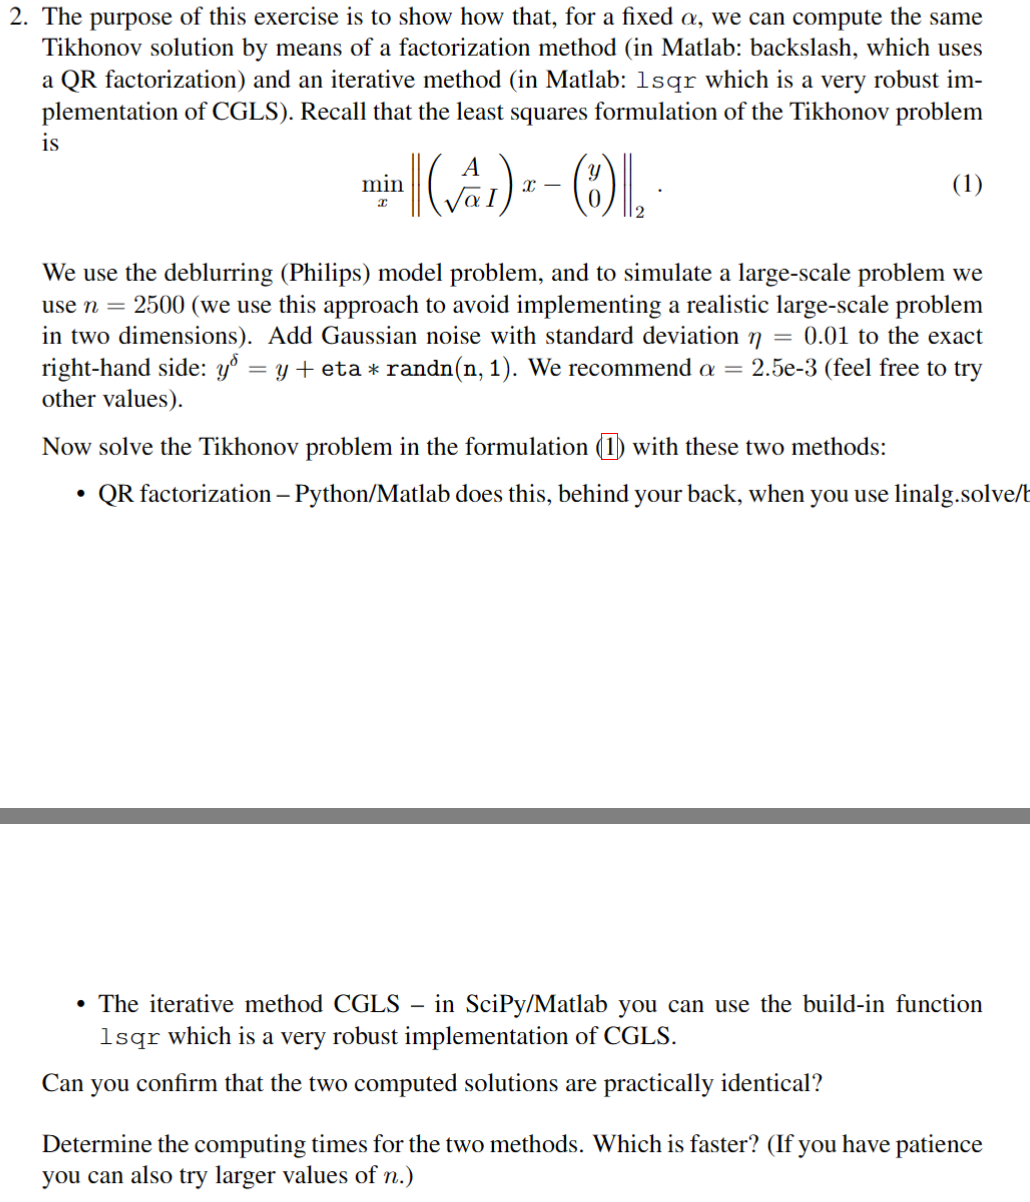

CGLS time: 0.0997 seconds
QR time: 4.5113 seconds


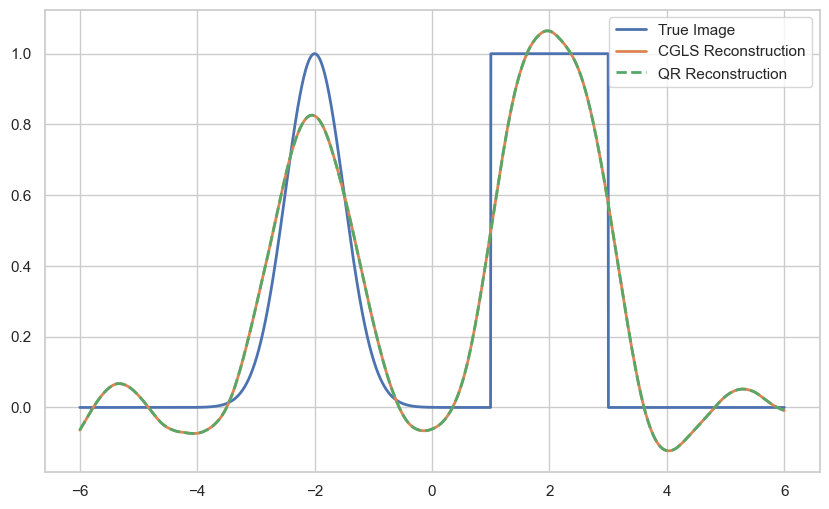

In [137]:

# Philips problem
alpha = 2.5e-3
eta = 0.01
# Number of points on interval (-6,6); n/4 must be a positive integer
n = 2500
assert n % 4 == 0

# Setup
h = 12 / n
n4 = n // 4
r1 = np.zeros(n)

# Cosine values for the formula
c = np.cos(np.arange(-1, n4 + 1) * 4 * np.pi / n)

# Fill in the first n/4 entries
r1[:n4] = h + 9 / (h * np.pi**2) * (2 * c[1:n4 + 1] - c[:n4] - c[2:n4 + 2])

# Middle entry
r1[n4] = h / 2 + 9 / (h * np.pi**2) * (np.cos(4 * np.pi / n) - 1)

# Construct Toeplitz matrix
A = scipy.linalg.toeplitz(r1)


# Set up true image
def heaviside_step(x):
    return 0.5 * (np.sign(x) + 1)

def tophat_func(s, width, center):
    return heaviside_step(s - (center - width / 2)) - heaviside_step(
        s - (center + width / 2)
    )

def x_deblur_func(s):
    return np.exp(-((s + 2) ** 2) / 0.5) + tophat_func(s, 2, 2)

# def x_deblur_func(s):
#     return np.exp(-((s + 2) ** 2) / 0.5)

s = np.linspace(-6, 6, n)

x_true = x_deblur_func(s)
y_true = A @ x_true


# Add noise
np.random.seed(42)
unscaled_noise = np.random.randn(*y_true.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)

noise_coeff = eta * np.linalg.norm(y_true) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
y_noisy = y_true + noise

# Modify A according to (1)
A_mod = np.vstack([A, np.sqrt(alpha) * np.eye(n)])
b_mod = np.vstack([y_noisy[:, None], np.zeros((n, 1))])

# Solve with CGLS
cgls_start = perf_counter()
x_cgls = scipy.sparse.linalg.lsqr(A_mod, b_mod)[0]
cgls_time = perf_counter() - cgls_start

# Solve with QR Factorisation
qr_start = perf_counter()
x_qr = scipy.linalg.lstsq(A_mod, b_mod)[0].flatten()
qr_time = perf_counter() - qr_start
# Plot
plt.figure(figsize=(10, 6))
plt.plot(s, x_true, label="True Image", linewidth=2)
plt.plot(s, x_cgls, label="CGLS Reconstruction", linewidth=2)
plt.plot(s, x_qr, label="QR Reconstruction", linewidth=2, ls="--")
plt.legend()

print(f"CGLS time: {cgls_time:.4f} seconds")
print(f"QR time: {qr_time:.4f} seconds")

## Comments

Yes, solutions are identical.

CGLS is much much faster than QR factorisation.
Probably should do convergence plot, but too lazy to do so here.

# 3
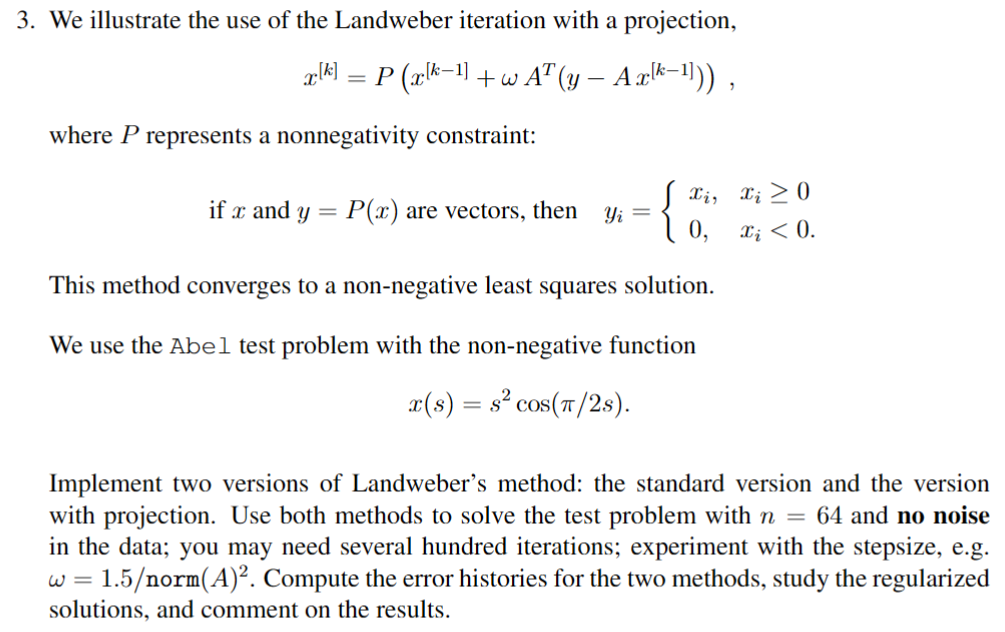

Comment: The problem is wrong, it should be:
$$
x(s) = s^2 \cos(\frac{π}{2} s)
$$

Text(0.5, 1.0, 'Landweber with Projection')

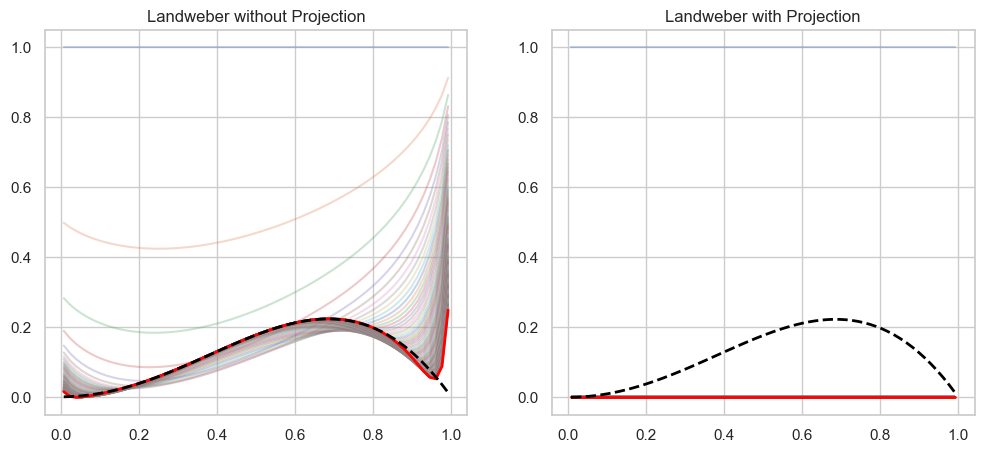

In [143]:
# Set up Abel problem

N = 64
h = 1 / N  # grid spacing

# Create s and t vectors with offset to avoid singularity at s = t
svec = np.linspace(h/2, 1 - h/2, N)  # midpoints of intervals
tvec = svec + h/2                    # shifted t values
tvec = tvec.reshape(-1, 1)           # make tvec a column vector

# Create matrices for pairwise differences
sMatrix = np.tile(svec, (N, 1))      # each row is svec
tMatrix = np.tile(tvec, (1, N))      # each column is tvec

# Initialize matrix A
A = np.zeros((N, N))

# Compute entries of A where s < t
index = sMatrix < tMatrix
A[index] = h / np.sqrt(np.abs(tMatrix[index] - sMatrix[index]))

# Set up true image
def x_abel_func(s):
    return s ** 2 * np.cos(np.pi / 2 * s)

x_true = x_abel_func(svec)
y_true = A @ x_true

# Landweber step no projection
def landweber_step_no_projection(A, y, xk, omega):
    dk = -omega * (A.T @ (A @ xk - y))
    return xk + dk

# Now with projection
def landweber_step_with_projection(A, y, xk, omega):
    xk1_candidate = landweber_step_no_projection(A, y, xk, omega)
    xk1 = np.minimum(xk1_candidate, 0)
    return xk1

# Solve with no noise
omega = 1.5 / np.linalg.norm(A) ** 2

xk = np.ones_like(x_true)
xk_no_proj = xk.copy()
xk_proj = xk.copy()

history_no_proj = [xk.copy()]
history_proj = [xk.copy()]
for k in range(100):
    xk_no_proj = landweber_step_no_projection(A, y_true, xk_no_proj, omega)
    history_no_proj.append(xk_no_proj.copy())

    xk_proj = landweber_step_with_projection(A, y_true, xk_proj, omega)
    history_proj.append(xk_proj.copy())

fig, (ax_no_proj, ax_proj) = plt.subplots(1, 2, figsize=(12, 5))
for xk_no_proj, xk_proj in zip(history_no_proj, history_proj):
    ax_no_proj.plot(svec, xk_no_proj, alpha=0.3)
    ax_proj.plot(svec, xk_proj, alpha=0.3)

ax_no_proj.plot(svec, history_no_proj[-1], label="Final Reconstruction", linewidth=2, color="red")
ax_no_proj.plot(svec, x_true, label="True Image", linewidth=2, color="black", ls="--")
ax_proj.plot(svec, history_proj[-1], label="Final Reconstruction", linewidth=2, color="red")
ax_proj.plot(svec, x_true, label="True Image", linewidth=2, color="black", ls="--")

ax_no_proj.set_title("Landweber without Projection")
ax_proj.set_title("Landweber with Projection")

# 4
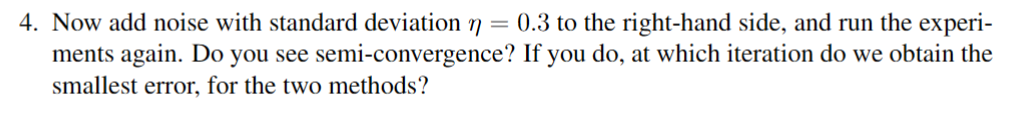

Text(0.5, 1.0, 'Landweber with Projection')

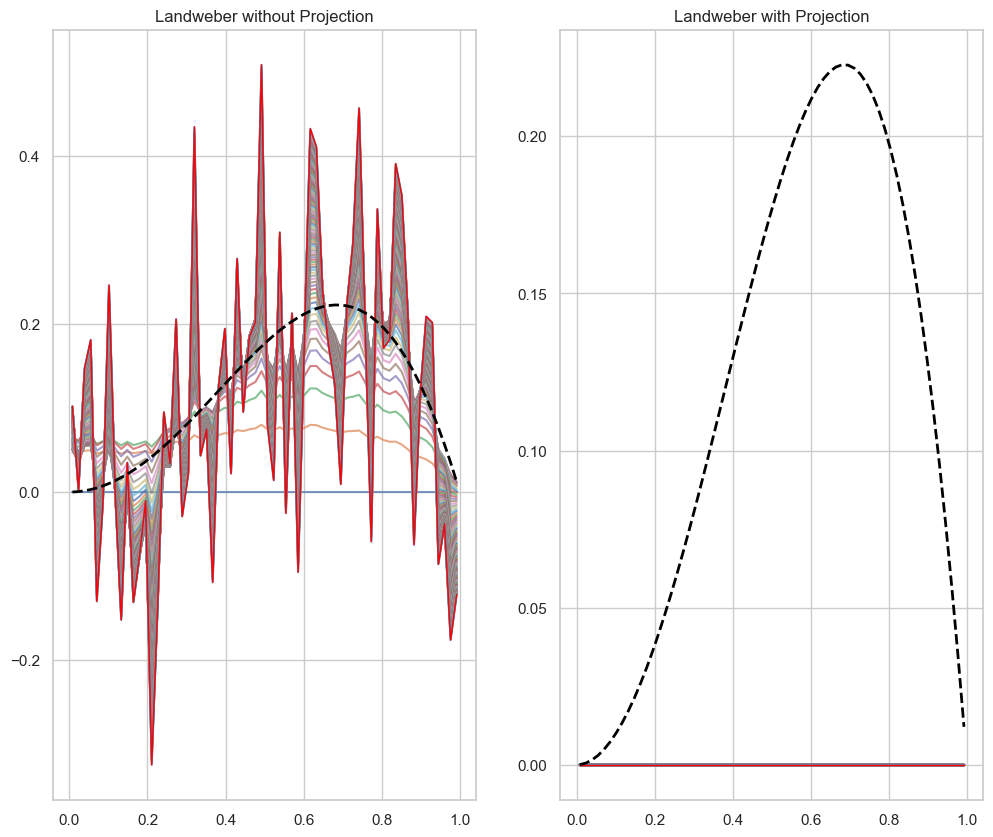

In [144]:
# Set up Abel problem

N = 64
h = 1 / N  # grid spacing
eta = 0.3

# Create s and t vectors with offset to avoid singularity at s = t
svec = np.linspace(h/2, 1 - h/2, N)  # midpoints of intervals
tvec = svec + h/2                    # shifted t values
tvec = tvec.reshape(-1, 1)           # make tvec a column vector

# Create matrices for pairwise differences
sMatrix = np.tile(svec, (N, 1))      # each row is svec
tMatrix = np.tile(tvec, (1, N))      # each column is tvec

# Initialize matrix A
A = np.zeros((N, N))

# Compute entries of A where s < t
index = sMatrix < tMatrix
A[index] = h / np.sqrt(np.abs(tMatrix[index] - sMatrix[index]))

# Set up true image

x_true = x_abel_func(svec)
y_true = A @ x_true

# Add noise
np.random.seed(42)
unscaled_noise = np.random.randn(*y_true.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)

noise_coeff = eta * np.linalg.norm(y_true) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
y_noisy = y_true + noise

# Landweber step no projection
def landweber_step_no_projection(A, y, xk, omega):
    dk = -omega * (A.T @ (A @ xk - y))
    return xk + dk

# Now with projection
def landweber_step_with_projection(A, y, xk, omega):
    xk1_candidate = landweber_step_no_projection(A, y, xk, omega)
    xk1 = np.minimum(xk1_candidate, 0)
    return xk1

omega = 1.5 / np.linalg.norm(A) ** 2

xk = np.zeros_like(x_true)
xk_no_proj = xk.copy()
xk_proj = xk.copy()

history_no_proj = [xk.copy()]
history_proj = [xk.copy()]
for k in range(100):
    xk_no_proj = landweber_step_no_projection(A, y_noisy, xk_no_proj, omega)
    history_no_proj.append(xk_no_proj.copy())

    xk_proj = landweber_step_with_projection(A, y_noisy, xk_proj, omega)
    history_proj.append(xk_proj.copy())

fig, (ax_no_proj, ax_proj) = plt.subplots(1, 2, figsize=(12, 10))
for xk_no_proj, xk_proj in zip(history_no_proj, history_proj):
    ax_no_proj.plot(svec, xk_no_proj, alpha=0.7)
    ax_proj.plot(svec, xk_proj, alpha=0.7)

ax_no_proj.plot(svec, history_no_proj[-1], label="Final Reconstruction", linewidth=1, color="red")
ax_no_proj.plot(svec, x_true, label="True Image", linewidth=2, color="black", ls="--")
ax_proj.plot(svec, history_proj[-1], label="Final Reconstruction", linewidth=1, color="red")
ax_proj.plot(svec, x_true, label="True Image", linewidth=2, color="black", ls="--")

ax_no_proj.set_title("Landweber without Projection")
ax_proj.set_title("Landweber with Projection")

Minimum error (no projection): 0.2285 at iteration 8
Minimum error (projection): 1.1468 at iteration 0


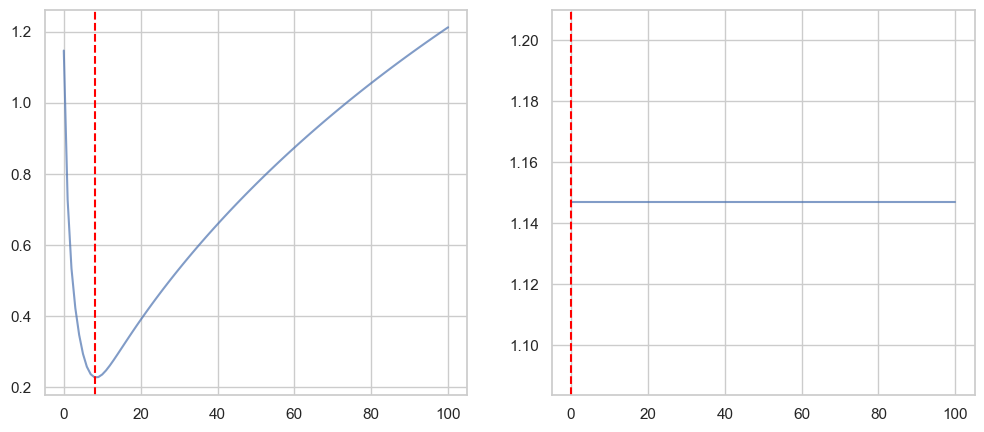

In [145]:
# Compare error histories
error_no_proj = [np.linalg.norm(xk - x_true) for xk in history_no_proj]
error_proj = [np.linalg.norm(xk - x_true) for xk in history_proj]

fig, (ax_no_proj, ax_proj) = plt.subplots(1, 2, figsize=(12, 5))
ax_no_proj.plot(error_no_proj, alpha=0.7)
ax_proj.plot(error_proj, alpha=0.7)

# Find index of minimum errors
min_err_idx_no_proj = np.argmin(error_no_proj)
min_err_idx_proj = np.argmin(error_proj)
min_err_no_proj = error_no_proj[min_err_idx_no_proj]
min_err_proj = error_proj[min_err_idx_proj]
ax_no_proj.axvline(min_err_idx_no_proj, color='red', linestyle='--', label='Min Error Point')
ax_proj.axvline(min_err_idx_proj, color='red', linestyle='--', label='Min Error Point')

print(f"Minimum error (no projection): {min_err_no_proj:.4f} at iteration {min_err_idx_no_proj}")
print(f"Minimum error (projection): {min_err_proj:.4f} at iteration {min_err_idx_proj}")

# 5
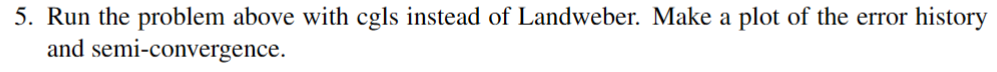

Text(0.5, 1.0, 'CGLS')

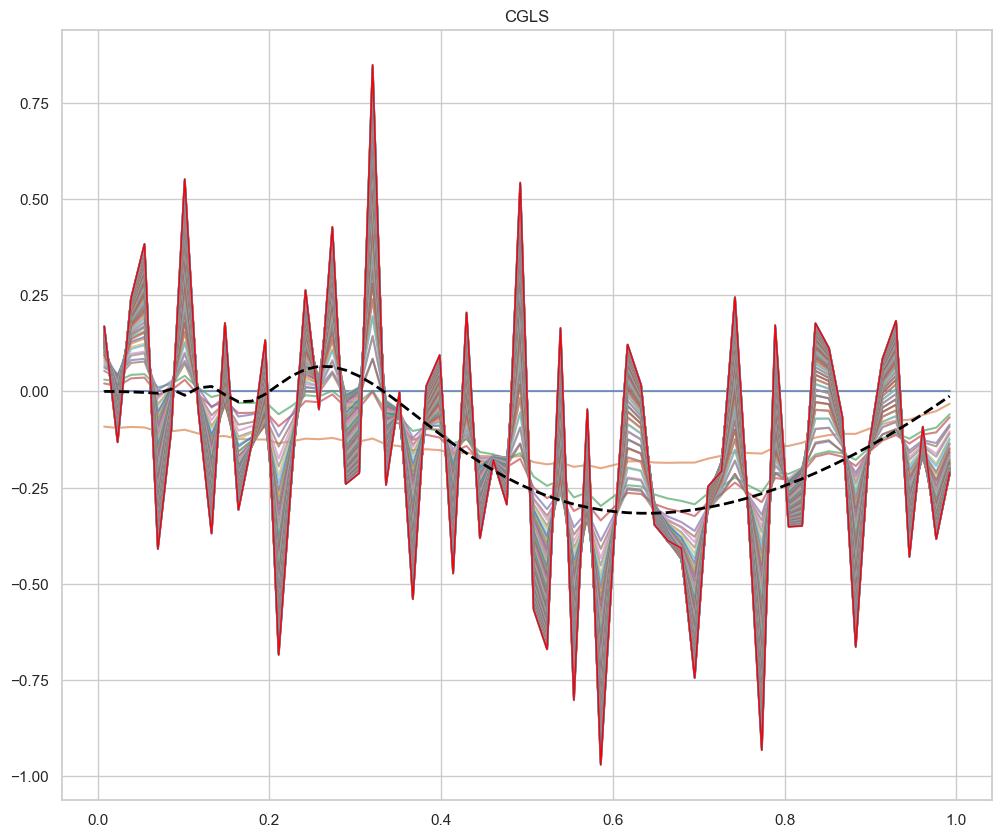

In [184]:
# Set up Abel problem

N = 64
h = 1 / N  # grid spacing
eta = 0.3

# Create s and t vectors with offset to avoid singularity at s = t
svec = np.linspace(h/2, 1 - h/2, N)  # midpoints of intervals
tvec = svec + h/2                    # shifted t values
tvec = tvec.reshape(-1, 1)           # make tvec a column vector

# Create matrices for pairwise differences
sMatrix = np.tile(svec, (N, 1))      # each row is svec
tMatrix = np.tile(tvec, (1, N))      # each column is tvec

# Initialize matrix A
A = np.zeros((N, N))

# Compute entries of A where s < t
index = sMatrix < tMatrix
A[index] = h / np.sqrt(np.abs(tMatrix[index] - sMatrix[index]))

# Set up true image
def x_abel_func(s):
    return s ** 2 * np.cos(np.pi / (2 * s))

x_true = x_abel_func(svec)
y_true = A @ x_true

# Add noise
np.random.seed(42)
unscaled_noise = np.random.randn(*y_true.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)

noise_coeff = eta * np.linalg.norm(y_true) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
y_noisy = y_true + noise

xk = np.zeros_like(x_true)

history = [xk.copy()]
for k in range(100):
    xk = scipy.sparse.linalg.lsqr(A, y_noisy, x0=xk, iter_lim=1)[0]
    history.append(xk.copy())


fig, ax = plt.subplots(figsize=(12, 10))
for xk in history:
    ax.plot(svec, xk, alpha=0.7)

ax.plot(svec, history[-1], label="Final Reconstruction", linewidth=1, color="red")
ax.plot(svec, x_true, label="True Image", linewidth=2, color="black", ls="--")

ax.set_title("CGLS")


Minimum error: 0.3401 at iteration 2


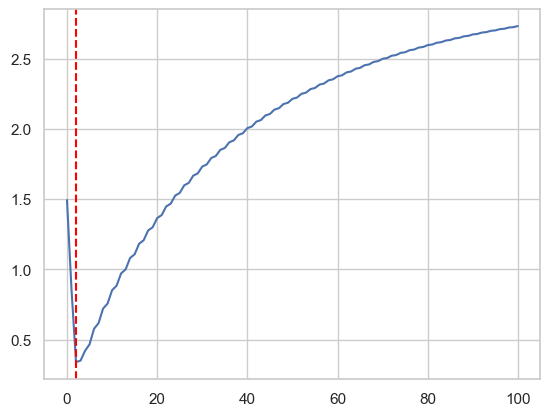

In [185]:
# Error history
error = [np.linalg.norm(xk - x_true) for xk in history]

# Index of minimum error
min_error_index = np.argmin(error)
min_error = error[min_error_index]
print(f"Minimum error: {min_error:.4f} at iteration {min_error_index}")
plt.figure()
plt.plot(error)
plt.axvline(min_error_index, color='red', linestyle='--', label='Min Error Point')

## Comments

Yes, we observe semi-convergence

# 6
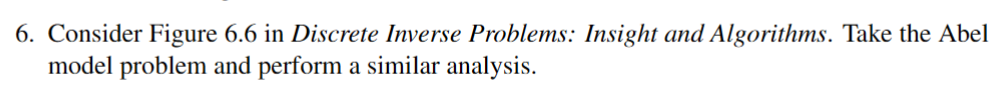

---

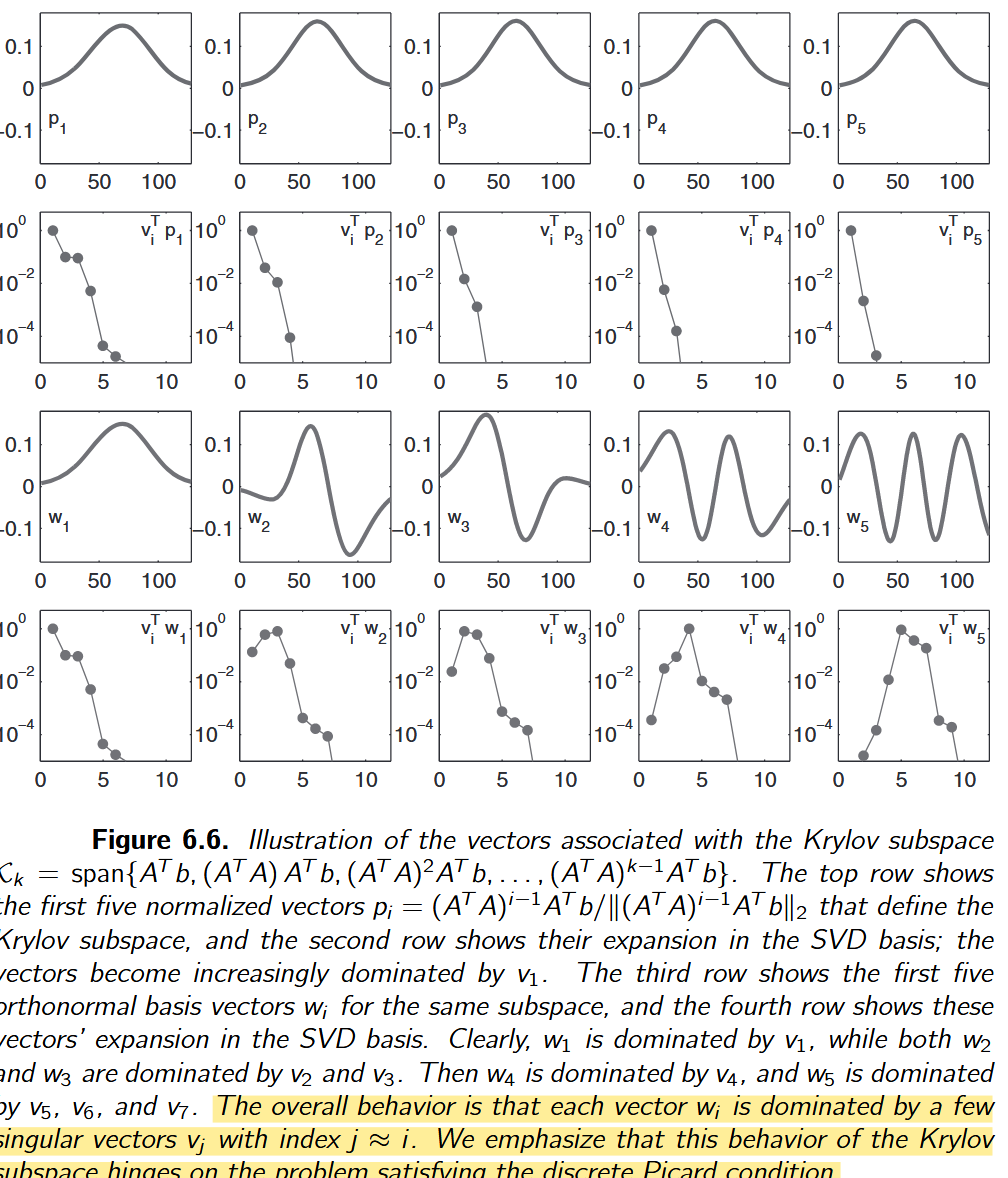

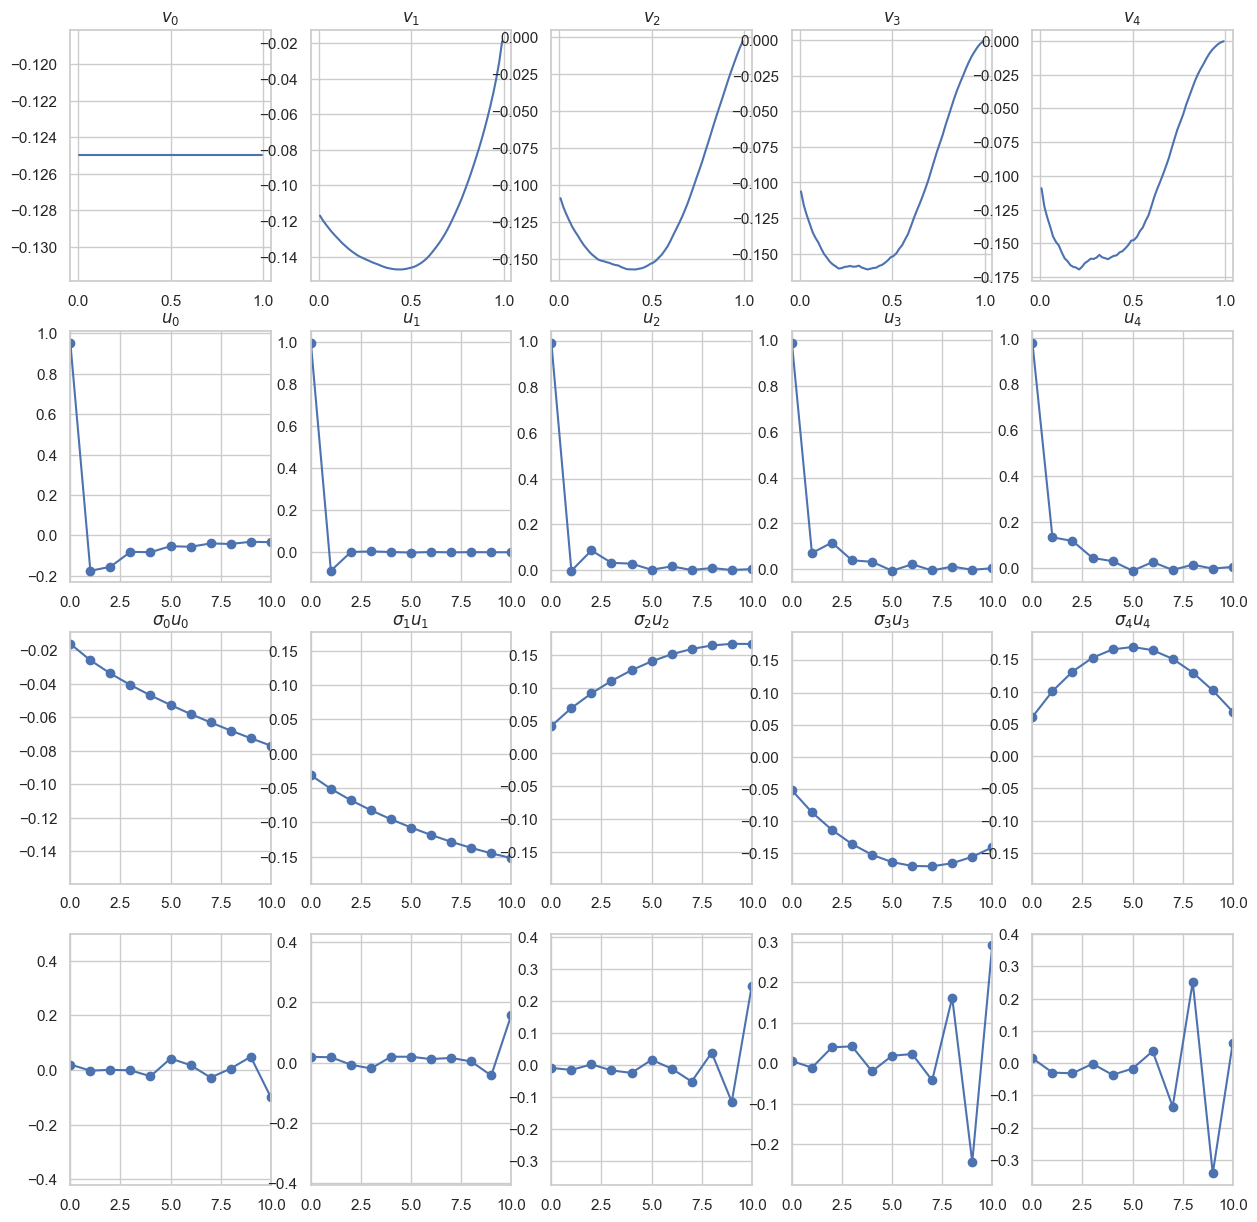

In [ ]:
# Construct Krylov subspace
k_max = 5
vectors = []
for k in range(k_max):
    v = ((A.T @ A) ** k) @ A.T @ y_noisy
    # Normalisation
    v /= np.linalg.norm(v)
    vectors.append(v)

K = np.column_stack(vectors)

fig, axs = plt.subplots(4, k_max, figsize=(15, 15))

# First row
for i in range(k_max):
    ax = axs[0, i]
    ax.plot(svec, K[:, i])
    ax.set_title(f'$v_{{{i}}}$')

# Second row
U, S, VT = np.linalg.svd(A, full_matrices=False)
for i in range(k_max):

    ax = axs[1, i]
    v = VT.T
    p = K[:, i]
    x = v.T @ p
    ax.plot(x, marker="o")
    ax.set_title(f'$u_{{{i}}}$')
    ax.set_xlim(0, 10)

# Third row
for i in range(k_max):
    ax = axs[2, i]

    ax.plot(U[:, i], marker="o")
    ax.set_title(f'$σ_{{{i}}} u_{{{i}}}$')
    ax.set_xlim(0, 10)

# Fourth row
for i in range(k_max):
    ax = axs[3, i]

    v = VT.T
    x = v @ U[:, i]

    ax.plot(x, marker="o")
    ax.set_xlim(0, 10)

^ This seems wrong

In [182]:
K.shape
U.shape
VT.shape

(64, 64)